<a href="https://colab.research.google.com/github/maliboo-wow/ml-lab/blob/main/%D0%9B%D0%912_1_%D0%91%D1%96%D0%B1%D1%96%D0%BA%D0%BE%D0%B2%D0%B0%D0%90_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Лабораторна робота 2. Бібікова Анастасія

# Завдання 1

**Був присутній на парі**

Обробка та нааліз даних про ВВП країн. Датасет було отримано з Вікіпедії з використанням бібілотеки Pandas.

In [7]:
import numpy as np
import pandas as pd
import requests
import re

1. Вивести перші 5 рядків датасета

In [6]:
url = "https://en.wikipedia.org/wiki/List_of_countries_by_GDP_(nominal)"
html = requests.get(url, headers={"user-Agent": "Mozilla/5.0"}).text

tables = pd.read_html(html)
df = tables[2]
df.head()

/tmp/ipykernel_2032/3859462084.py:4: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  tables = pd.read_html(html)


,Country/Territory,IMF (2026)[1],World Bank (2025)[6],United Nations (2024)[7]
0,World,126295331,118350166,111565144
1,United States,32383920,30769700,29298000
2,China[n 1],20851593,19498039,18743802
3,Germany,5452858,5050923,4659929
4,Japan,4379253,4435163,4026211


2.	Визначити розмір датасета.

In [8]:
print('Рядків:', df.shape[0])
print('Стовпців:', df.shape[1])
print('Розмір:', df.shape)

Рядків: 222
Стовпців: 4
Розмір: (222, 4)


 3.	Визначити оптимальну кількість стовпців (видалити зайві, на власний розсуд).

In [9]:
df.columns = (df.columns
              .str.replace(r'(?:\s*\[\d+\])+', '', regex=True)
              .str.replace('Country/Territory', 'Country', regex=False))
df.head()

,Country,IMF (2026),World Bank (2025),United Nations (2024)
0,World,126295331,118350166,111565144
1,United States,32383920,30769700,29298000
2,China[n 1],20851593,19498039,18743802
3,Germany,5452858,5050923,4659929
4,Japan,4379253,4435163,4026211


In [10]:
df = df.drop(df[df.iloc[:, 0] == "World"].index)
df

,Country,IMF (2026),World Bank (2025),United Nations (2024)
1,United States,32383920,30769700,29298000
2,China[n 1],20851593,19498039,18743802
3,Germany,5452858,5050923,4659929
4,Japan,4379253,4435163,4026211
5,United Kingdom,4264794,4002588,3685881
...,...,...,...,...
217,Palau,377,345,310
218,Marshall Islands,342,308,281
219,Nauru,196,176,187
220,Montserrat,—N/a,—N/a,81


In [11]:
df.isnull().sum()

,0
Country,0
IMF (2026),0
World Bank (2025),0
United Nations (2024),0


In [15]:
df['IMF (2026)'] = pd.to_numeric(df['IMF (2026)'], errors='coerce')
df['World Bank (2025)'] = pd.to_numeric(df['World Bank (2025)'], errors='coerce')
df['United Nations (2024)'] = pd.to_numeric(df['United Nations (2024)'], errors='coerce')

In [13]:
df.dtypes

,0
Country,object
IMF (2026),float64
World Bank (2025),float64
United Nations (2024),float64


In [14]:
df

,Country,IMF (2026),World Bank (2025),United Nations (2024)
1,United States,32383920.0,30769700.0,29298000.0
2,China[n 1],20851593.0,19498039.0,18743802.0
3,Germany,5452858.0,5050923.0,4659929.0
4,Japan,4379253.0,4435163.0,4026211.0
5,United Kingdom,4264794.0,4002588.0,3685881.0
...,...,...,...,...
217,Palau,377.0,345.0,310.0
218,Marshall Islands,342.0,308.0,281.0
219,Nauru,196.0,176.0,187.0
220,Montserrat,NaN,NaN,81.0


In [16]:
df.isnull().sum()

,0
Country,0
IMF (2026),31
World Bank (2025),35
United Nations (2024),9


4.	Замініть у таблиці значення "—" на значення NaN. Перевірити наявність пропущених значень. При наявності, замінити пропущені значення на середнє значення.

In [17]:
df.iloc[:, 1:] = df.iloc[:, 1:].apply(lambda r: r.fillna(r.mean()), axis=1)

df.isnull().sum()

,0
Country,0
IMF (2026),8
World Bank (2025),8
United Nations (2024),8


In [18]:
df.iloc[:, 1:] = (df.iloc[:, 1:]
                  .apply(lambda r: r.fillna(r.mean()), axis=1)
                  .fillna(df.iloc[:, 1:].mean()))
df.isnull().sum()

,0
Country,0
IMF (2026),0
World Bank (2025),0
United Nations (2024),0


In [20]:
df.tail(10)

,Country,IMF (2026),World Bank (2025),United Nations (2024)
212,Saint Martin,594338.521127,556140.901408,524623.732394
213,Federated States of Micronesia,521.000000,502.000000,471.000000
214,Anguilla,456.000000,456.000000,456.000000
215,Cook Islands,414.000000,414.000000,414.000000
216,Kiribati,401.000000,349.000000,343.000000
217,Palau,377.000000,345.000000,310.000000
218,Marshall Islands,342.000000,308.000000,281.000000
219,Nauru,196.000000,176.000000,187.000000
220,Montserrat,81.000000,81.000000,81.000000
221,Tuvalu,65.000000,57.000000,56.000000


5. Ще раз вивести датасет

In [21]:
df

,Country,IMF (2026),World Bank (2025),United Nations (2024)
1,United States,32383920.0,30769700.0,29298000.0
2,China[n 1],20851593.0,19498039.0,18743802.0
3,Germany,5452858.0,5050923.0,4659929.0
4,Japan,4379253.0,4435163.0,4026211.0
5,United Kingdom,4264794.0,4002588.0,3685881.0
...,...,...,...,...
217,Palau,377.0,345.0,310.0
218,Marshall Islands,342.0,308.0,281.0
219,Nauru,196.0,176.0,187.0
220,Montserrat,81.0,81.0,81.0


6.	Перевірити наявність дублікатів. При наявності видалити дублікати.

In [22]:
print('Дублікатів:', df.duplicated().sum())
df = df.drop_duplicates()
print('Після видалення:', df.shape)

Дублікатів: 0
Після видалення: (221, 4)


7.	Вивести описову статистику датасету describe()

In [23]:
df.describe()

,IMF (2026),World Bank (2025),United Nations (2024)
count,2.210000e+02,2.210000e+02,2.210000e+02
mean,5.943385e+05,5.561409e+05,5.246237e+05
std,2.673673e+06,2.527950e+06,2.410273e+06
min,6.500000e+01,5.700000e+01,5.600000e+01
25%,9.442000e+03,9.233000e+03,8.840000e+03
50%,4.884900e+04,4.809900e+04,4.276500e+04
75%,3.773650e+05,3.348550e+05,2.986970e+05
max,3.238392e+07,3.076970e+07,2.929800e+07


8. Визначте відхилення (різницю) між показниками IMF (2026) та World Bank (2025) для кожної країни. У яких країнах ці показники найбільше відрізняються (дати відповідь)?

In [24]:
df['IMF_WB_Diff'] = abs(df['IMF (2026)'] - df['World Bank (2025)'])

max_diff = df['IMF_WB_Diff'].max()

country = df[df['IMF_WB_Diff'] == max_diff]['Country'].values[0]
print(f'{country} has the largest difference between IMF and WB: {max_diff}')

df.head(10)

United States has the largest difference between IMF and WB: 1614220.0


,Country,IMF (2026),World Bank (2025),United Nations (2024),IMF_WB_Diff
1,United States,32383920.0,30769700.0,29298000.0,1614220.0
2,China[n 1],20851593.0,19498039.0,18743802.0,1353554.0
3,Germany,5452858.0,5050923.0,4659929.0,401935.0
4,Japan,4379253.0,4435163.0,4026211.0,55910.0
5,United Kingdom,4264794.0,4002588.0,3685881.0,262206.0
6,India,4153191.0,3956067.0,3952244.0,197124.0
7,France,3596094.0,3366316.0,3160443.0,229778.0
8,Italy,2738164.0,2551557.0,2380825.0,186607.0
9,Russia,2656452.0,2561310.0,2173386.0,95142.0
10,Brazil,2635912.0,2279920.0,2185822.0,355992.0


9.	Обчисліть кореляцію між показниками IMF (2026), World Bank (2025) та United Nations (2024). Які пари змінних мають найвищу кореляцію?

In [25]:
cor_IMF_WB = df['IMF (2026)'].corr(df['World Bank (2025)'])
cor_IMF_UN = df['IMF (2026)'].corr(df['United Nations (2024)'])
cor_WB_UN = df['World Bank (2025)'].corr(df['United Nations (2024)'])

print(f'Correlation between IMF and WB: {cor_IMF_WB}')
print(f'Correlation between IMF and UN: {cor_IMF_UN}')
print(f'Correlation between WB and UN: {cor_WB_UN}')

Correlation between IMF and WB: 0.9998772853399375
Correlation between IMF and UN: 0.9998162531253877
Correlation between WB and UN: 0.9998603541665632


In [26]:
# Find highest correlation
max_cor = max(cor_IMF_WB, cor_IMF_UN, cor_WB_UN)
if max_cor == cor_IMF_WB:
    print('IMF and WB have the highest correlation')
elif max_cor == cor_IMF_UN:
    print('IMF and UN have the highest correlation')
else:
    print('WB and UN have the highest correlation')

IMF and WB have the highest correlation


Обчислити середнє значення за стовпцями

In [27]:
# Find mean of IMF, WB and UN by columns
mean_IMF = df['IMF (2026)'].mean()
mean_IMF

np.float64(594338.5211267605)

In [28]:
mean_WB = df['World Bank (2025)'].mean()
mean_WB

np.float64(556140.9014084507)

In [29]:
mean_UN = df['United Nations (2024)'].mean()
mean_UN

np.float64(524623.7323943662)

11.	Обчисліть стандартне відхилення показників для кожної країни. Яка країна має найвищу варіативність у показниках між роками?

In [31]:
# Find standard deviation for each row
df['std'] = df[['IMF (2026)', 'World Bank (2025)', 'United Nations (2024)']].std(axis=1)

# Find country with the highest standard deviation
max_std = df['std'].max()
country = df[df['std'] == max_std]['Country'].values[0]
print(f'{country} has the highest standard deviation: {max_std}')

df.head(10)

United States has the highest standard deviation: 1543508.4140144275


,Country,IMF (2026),World Bank (2025),United Nations (2024),IMF_WB_Diff,std
1,United States,32383920.0,30769700.0,29298000.0,1614220.0,1.543508e+06
2,China[n 1],20851593.0,19498039.0,18743802.0,1353554.0,1.068002e+06
3,Germany,5452858.0,5050923.0,4659929.0,401935.0,3.964771e+05
4,Japan,4379253.0,4435163.0,4026211.0,55910.0,2.217380e+05
5,United Kingdom,4264794.0,4002588.0,3685881.0,262206.0,2.898838e+05
6,India,4153191.0,3956067.0,3952244.0,197124.0,1.149291e+05
7,France,3596094.0,3366316.0,3160443.0,229778.0,2.179348e+05
8,Italy,2738164.0,2551557.0,2380825.0,186607.0,1.787283e+05
9,Russia,2656452.0,2561310.0,2173386.0,95142.0,2.558938e+05
10,Brazil,2635912.0,2279920.0,2185822.0,355992.0,2.374046e+05


12.	Визначення країни з найвищим та найнижчим показниками: Знайдіть країну з найвищим та найнижчим показниками у кожному з років (IMF (2026), World Bank (2025), United Nations (2024)).

In [32]:
# Find max and min GDP for each year (with country names)
for col in ['IMF (2026)', 'World Bank (2025)', 'United Nations (2024)']:
    max_country = df.loc[df[col].idxmax(), 'Country']
    min_country = df.loc[df[col].idxmin(), 'Country']
    print(f'{col}:')
    print(f'   Max: {max_country} = {df[col].max():,.0f}')
    print(f'   Min: {min_country} = {df[col].min():,.0f}')
    print()

IMF (2026):
   Max: United States = 32,383,920
   Min: Tuvalu = 65

World Bank (2025):
   Max: United States = 30,769,700
   Min: Tuvalu = 57

United Nations (2024):
   Max: United States = 29,298,000
   Min: Tuvalu = 56



У кожному з трьох років найбільший ВВП має США, найменший — Tuvalu. Лідер і аутсайдер не змінюються від року до року.

13.	Побудуйте гістограму для розподілу показників IMF (2026) серед всіх країн. Який вигляд має розподіл? Чи є країни, що виділяються?

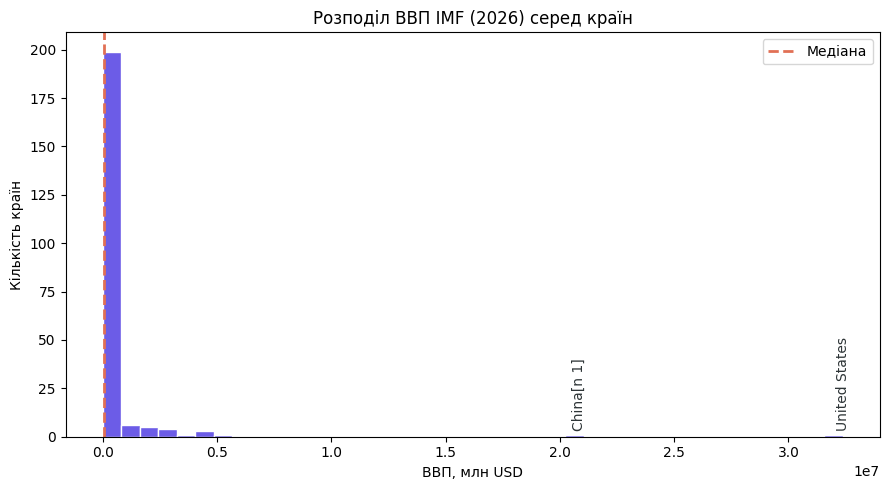

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.hist(df['IMF (2026)'], bins=40, color='#6C5CE7', edgecolor='white')

plt.axvline(df['IMF (2026)'].median(), color='#E17055', linestyle='--',
            linewidth=2, label='Медіана')

# два найбільші викиди — беремо через nlargest, без пошуку за назвою
top2 = df.nlargest(2, 'IMF (2026)')
labels = top2['Country'] if 'Country' in df.columns else top2.index
for x, name in zip(top2['IMF (2026)'], labels):
    plt.text(x, 3, name, rotation=90, va='bottom', ha='center', color='#2D3436')

plt.title('Розподіл ВВП IMF (2026) серед країн')
plt.xlabel('ВВП, млн USD')
plt.ylabel('Кількість країн')
plt.legend()
plt.tight_layout()
plt.show()

Вісь X - розмір ВВП у млн USD (1e7 = ×10⁷, тобто 3.0 означає 30 млн), вісь Y - кількість країн у цьому діапазоні.
Майже всі країни (200) зібрані в лівому стовпчику біля нуля - типова країна дуже мала.
Помаранчева пунктирна лінія - медіана (41 тис.), майже на осі.
Дві підписані рисочки праворуч (Китай, США) - поодинокі гіганти, що розтягують усю вісь.
Висновок: розподіл різко скошений вправо - багато малих країн і кілька велетнів-викидів (США, Китай).

14.	Розрахуйте частку кожної країни в загальному значенні для кожного року (IMF (2026), World Bank (2025), United Nations (2024)).
 Як змінюються частки країн з часом (дати відповідь)?

In [37]:
share = pd.DataFrame()
share['Country'] = df['Country']

for col in ['IMF (2026)', 'World Bank (2025)', 'United Nations (2024)']:
    share[col] = df[col] / df[col].sum() * 100

# топ-6 країн за часткою
share.sort_values('IMF (2026)', ascending=False).head(6)

,Country,IMF (2026),World Bank (2025),United Nations (2024)
1,United States,24.654901,25.034917,25.269565
2,China[n 1],15.874976,15.864041,16.166555
3,Germany,4.151433,4.109544,4.019195
4,Japan,3.334064,3.608548,3.472613
5,United Kingdom,3.246922,3.256595,3.179077
6,India,3.161955,3.218745,3.408816


In [39]:
share['change'] = share['IMF (2026)'] - share['United Nations (2024)']

share.sort_values('IMF (2026)', ascending=False).head(6)

,Country,IMF (2026),World Bank (2025),United Nations (2024),change
1,United States,24.654901,25.034917,25.269565,-0.614664
2,China[n 1],15.874976,15.864041,16.166555,-0.291579
3,Germany,4.151433,4.109544,4.019195,0.132238
4,Japan,3.334064,3.608548,3.472613,-0.138549
5,United Kingdom,3.246922,3.256595,3.179077,0.067845
6,India,3.161955,3.218745,3.408816,-0.246860


Розподіл світового ВВП дуже сконцентрований. Найбільшу частку має США - близько 25–26%, на другому місці Китай із приблизно 16%. Разом ці дві країни дають понад 40% загального обсягу, тоді як решта країн мають по кілька відсотків або менше. З часом частки країн майже не змінюються: лідери залишаються тими самими, а коливання складають лише десяті частки відсотка. Слід враховувати, що три показники взяті з різних джерел (IMF, World Bank, United Nations) за різні роки, тому незначні зміни часток пояснюються радше відмінностями в методиці розрахунку, а не реальним перерозподілом ВВП між країнами.

15.	Візуалізуйте зміни в показниках для кожної країни за три роки на графіку. Які країни показують стабільне зростання або спад (дати відповідь)?

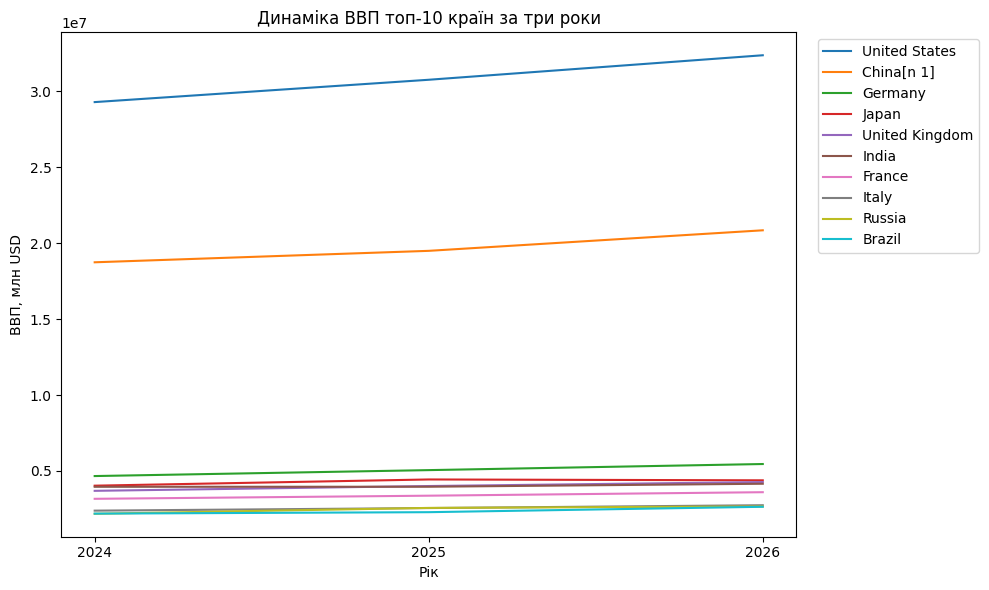

In [42]:
import matplotlib.pyplot as plt

# роки в хронологічному порядку
year_order = ['United Nations (2024)', 'World Bank (2025)', 'IMF (2026)']
years = [2024, 2025, 2026]

top10 = df.nlargest(10, 'IMF (2026)')

plt.figure(figsize=(10, 6))
for _, row in top10.iterrows():
    plt.plot(years, row[year_order], label=row['Country'])

plt.title('Динаміка ВВП топ-10 країн за три роки')
plt.xlabel('Рік')
plt.ylabel('ВВП, млн USD')
plt.xticks(years)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [43]:
a, b, c = year_order
grow = df[(df[a] < df[b]) & (df[b] < df[c])]   # весь час росте: 2024 < 2025 < 2026
fall = df[(df[a] > df[b]) & (df[b] > df[c])]   # весь час спадає

print('Стабільне зростання:', len(grow), 'країн')
print('Стабільний спад:', len(fall), 'країн')

Стабільне зростання: 170 країн
Стабільний спад: 3 країн


Більшість країн демонструють стабільне зростання ВВП протягом трьох років - близько 170 із 221, зокрема майже всі найбільші економіки: США, Китай, Німеччина, Велика Британія, Індія, Франція, Італія, *** та Бразилія. Стабільний спад показують лише поодинокі країни (3 із 221). Серед топ-10 винятком є Японія: її значення спершу зростає (2024 → 2025), а потім трохи знижується (2025 → 2026), тобто динаміка нерівномірна. Загалом переважає тенденція до зростання, а випадки послідовного спаду є рідкісними.